# Dynamic AU guidance G for POST (stage-4 cross-attention)

Plan: LibreFace gives image-level AU values p (per image). We build a region mask M_c per AU on the 7x7 token grid,
form a_c = p_c * M_c, and compute G = sum_c a_t,c a_s,c^T (49x49 per source/target pair).

Cells 1-4 need LibreFace and your images. Cells 5-6 validate landmark masks and the POST integration contract.
Run cell 2 once to catch LibreFace API drift before exporting both datasets.

## 2. Run LibreFace on a few real crops

The four samples below come from the prepared RAF-DB manifest and cover sadness, happiness, surprise, and anger. `get_facial_attributes` returns a dictionary; AU intensities are stored under `au_intensities` and use the documented `[0, 5]` scale. Results are saved to `notebooks/au_sample.csv` for the next cell.

In [1]:
from pathlib import Path
import pandas as pd
import libreface

REPO_ROOT = Path("/home/dangnha/cd-fer/CS-AUAlign-ViT")
SAMPLE_IMAGES = {
    "raf_db:train_00001.jpg": REPO_ROOT / "data/processed/raf-v5-deduplicated/crops/9a8b944c2f0fcec7131ea68569a1e17db4911a36ccd0f28a6bcaa41a2bf53fcd.png",  # sadness
    "raf_db:train_00003.jpg": REPO_ROOT / "data/processed/raf-v5-deduplicated/crops/cd27077a5b23e728fe1219da682abdaa008f588e897c2a3207b3db1fe85839d6.png",  # happiness
    "raf_db:train_00006.jpg": REPO_ROOT / "data/processed/raf-v5-deduplicated/crops/dfbf5d119915fc97d4a0172c1ad748b31e4f57da48244907aac9a7603906cc9f.png",  # surprise
    "raf_db:train_00023.jpg": REPO_ROOT / "data/processed/raf-v5-deduplicated/crops/73491ab50cebee509f76de49d769d98e75bd55c2ebf66dc755d0d49facdaae14.png",  # anger
}
assert all(path.is_file() for path in SAMPLE_IMAGES.values())

records = []
for sample_id, image_path in SAMPLE_IMAGES.items():
    out = libreface.get_facial_attributes(str(image_path), device="cpu")
    assert isinstance(out, dict), f"Unexpected result type: {type(out)!r}"
    assert isinstance(out.get("au_intensities"), dict), out.keys()
    records.append({"sample_id": sample_id, **out["au_intensities"]})

AU_CSV = REPO_ROOT / "notebooks/au_sample.csv"
pd.DataFrame(records).to_csv(AU_CSV, index=False)
print("saved:", AU_CSV)
pd.DataFrame(records)

/home/dangnha/cd-fer/CS-AUAlign-ViT/.venv-au/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Using device: cpu for inference...


Using device: cpu for inference...
Using device: cpu for inference...
Using device: cpu for inference...
saved: /home/dangnha/cd-fer/CS-AUAlign-ViT/notebooks/au_sample.csv


,sample_id,au_1_intensity,au_2_intensity,au_4_intensity,au_5_intensity,au_6_intensity,au_9_intensity,au_12_intensity,au_15_intensity,au_17_intensity,au_20_intensity,au_25_intensity,au_26_intensity
0,raf_db:train_00001.jpg,0.069,0.047,0.482,0.022,0.017,0.038,0.009,0.025,0.072,0.038,0.015,0.033
1,raf_db:train_00003.jpg,0.062,0.029,0.070,0.027,0.012,0.042,0.014,0.032,0.066,0.050,0.506,0.057
2,raf_db:train_00006.jpg,0.145,0.128,0.239,2.459,0.035,0.080,0.058,0.045,0.093,0.067,0.499,0.134
3,raf_db:train_00023.jpg,0.141,0.074,0.529,0.059,0.058,0.148,0.131,0.066,0.138,0.082,0.711,0.143


## 3. Run LibreFace offline

The official CLI accepts one image/video path plus `--output_path` and `--device`. For dataset export, iterate the usable manifest rows, run the Python API on each `processed_path`, and write `sample_id` beside the 12 intensities. Training must join by ID rather than CSV row order.

In [2]:
!libreface --help
# Single-image smoke check:
# !libreface --input_path=/home/dangnha/cd-fer/CS-AUAlign-ViT/data/processed/raf-v5-deduplicated/crops/9a8b944c2f0fcec7131ea68569a1e17db4911a36ccd0f28a6bcaa41a2bf53fcd.png --output_path=/home/dangnha/cd-fer/CS-AUAlign-ViT/notebooks/au_one_image.csv --device=cpu

usage: libreface [-h] --input_path INPUT_PATH [--output_path OUTPUT_PATH]
                 [--device DEVICE] [--temp TEMP] [--batch_size BATCH_SIZE]
                 [--num_workers NUM_WORKERS]

optional arguments:
  -h, --help            show this help message and exit
  --input_path INPUT_PATH
                        Path to the video or image which you want to process
                        through libreface
  --output_path OUTPUT_PATH
                        Path to the csv where results should be saved.
                        Defaults to 'sample_results.csv'
  --device DEVICE       Device to use while inference. Can be 'cpu', 'cuda:0',
                        'cuda:1', ... Defaults to 'cpu'
  --temp TEMP           Path where the temporary results for facial attributes
                        can be saved.
  --batch_size BATCH_SIZE
                        Number of frames to process in a single batch when
                        doing inference on a video.
  --num_workers NUM_WOR

## 4. Validate the CSV and normalize intensities to [0, 1]

LibreFace documents the exact intensity columns `au_<id>_intensity` and the `[0, 5]` scale. We still print `df.columns` and `describe()` and fail early if a different release or malformed export breaks that contract.

In [3]:
import numpy as np
import pandas as pd

AUS = (1, 2, 4, 5, 6, 9, 12, 15, 17, 20, 25, 26)
AU_COLS = {au: f"au_{au}_intensity" for au in AUS}

df = pd.read_csv(AU_CSV)
print(df.columns.tolist())

columns = [AU_COLS[au] for au in AUS]
missing = sorted(set(columns) - set(df.columns))
assert not missing, f"Missing LibreFace intensity columns: {missing}"
print(df[columns].describe().T[["count", "min", "mean", "max"]])

def au_matrix(df):
    values = df[columns].to_numpy(dtype=np.float32)
    if not np.isfinite(values).all():
        raise ValueError("AU intensity contains missing/non-finite values")
    if not ((0.0 <= values) & (values <= 5.0)).all():
        raise ValueError("AU intensity outside LibreFace's [0, 5] range")
    return values / 5.0                    # shape (N, C)

P = au_matrix(df)
print(P.shape)

['sample_id', 'au_1_intensity', 'au_2_intensity', 'au_4_intensity', 'au_5_intensity', 'au_6_intensity', 'au_9_intensity', 'au_12_intensity', 'au_15_intensity', 'au_17_intensity', 'au_20_intensity', 'au_25_intensity', 'au_26_intensity']
                 count    min     mean    max
au_1_intensity     4.0  0.062  0.10425  0.145
au_2_intensity     4.0  0.029  0.06950  0.128
au_4_intensity     4.0  0.070  0.33000  0.529
au_5_intensity     4.0  0.022  0.64175  2.459
au_6_intensity     4.0  0.012  0.03050  0.058
au_9_intensity     4.0  0.038  0.07700  0.148
au_12_intensity    4.0  0.009  0.05300  0.131
au_15_intensity    4.0  0.025  0.04200  0.066
au_17_intensity    4.0  0.066  0.09225  0.138
au_20_intensity    4.0  0.038  0.05925  0.082
au_25_intensity    4.0  0.015  0.43275  0.711
au_26_intensity    4.0  0.033  0.09175  0.143
(4, 12)


## 5. Region masks on the 7x7 grid and G for a batch of pairs

The prepared crops are not geometrically aligned, so fixed centers are unsafe. Build brow, eye, nose, mouth, and chin regions per image from the five MTCNN landmarks already stored in `processed.jsonl`. First inspect `M_mouth` and `M_eye` separately on the same 224×224 face. Only after both masks land correctly should aggregate activity or `G` be interpreted.

When this is connected to training, the image and mask must receive the same horizontal flip.

M_mouth [1.15012088e-11 3.75068622e-11 7.82362231e-11 1.04384258e-10
 8.90824359e-11 4.86271821e-11 1.69783736e-11 8.33468405e-08
 2.71804339e-07 5.66961489e-07 7.56450731e-07 6.45561670e-07
 3.52390970e-07 1.23038703e-07 6.94601622e-05 2.26518139e-04
 4.72498214e-04 6.30416092e-04 5.38002583e-04 2.93677964e-04
 1.02538826e-04 6.65707374e-03 2.17095371e-02 4.52843085e-02
 6.04191832e-02 5.15622571e-02 2.81461477e-02 9.82733909e-03
 7.33722597e-02 2.39275992e-01 4.99110013e-01 6.65922046e-01
 5.68303704e-01 3.10218364e-01 1.08313970e-01 9.29996669e-02
 3.03283393e-01 6.32624209e-01 8.44059229e-01 7.20327497e-01
 3.93203169e-01 1.37288451e-01 1.35560101e-02 4.42078188e-02
 9.22138765e-02 1.23033501e-01 1.04997866e-01 5.73148914e-02
 2.00117212e-02] peak token: (5, 3) peak center px: (112.0, 176.0)


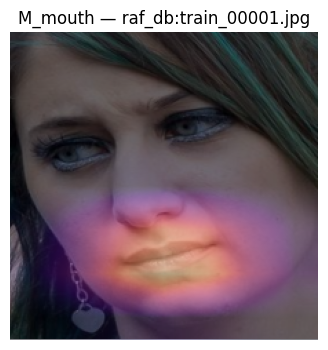

M_eye [2.3219739e-04 4.1455982e-04 5.3748646e-04 5.0605572e-04 3.4600272e-04
 1.7179525e-04 6.1943145e-05 7.9163708e-02 1.4133705e-01 1.8324678e-01
 1.7253099e-01 1.1796369e-01 5.8570642e-02 2.1118451e-02 4.1617453e-01
 7.4302834e-01 9.6335357e-01 9.0701920e-01 6.2015134e-01 3.0791393e-01
 1.1102261e-01 3.3736918e-02 6.0233116e-02 7.8093641e-02 7.3526926e-02
 5.0272170e-02 2.4960844e-02 8.9999763e-03 4.2171196e-05 7.5291478e-05
 9.7617158e-05 9.1908762e-05 6.2840285e-05 3.1201089e-05 1.1249983e-05
 8.1284357e-10 1.4512321e-09 1.8815562e-09 1.7715278e-09 1.2112371e-09
 6.0139643e-10 2.1684175e-10 2.4158981e-16 4.3132884e-16 5.5922788e-16
 5.2652574e-16 3.5999861e-16 1.7874440e-16 6.4448758e-17] peak token: (2, 2) peak center px: (80.0, 80.0)


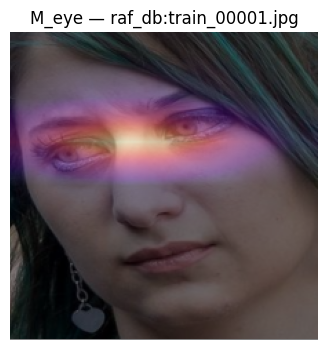

In [4]:
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

GRID = 7
AU2REGION = {1: "brow", 2: "brow", 4: "brow", 5: "eye", 6: "eye", 9: "nose",
             12: "mouth", 15: "mouth", 17: "chin", 20: "mouth", 25: "mouth", 26: "mouth"}

def landmark_regions(row):
    width, height = row["processed_size"]
    points = np.asarray(row["landmarks_crop"], dtype=np.float32) / (width, height)
    left_eye, right_eye, nose, left_mouth, right_mouth = points
    eye = (left_eye + right_eye) / 2
    mouth = (left_mouth + right_mouth) / 2
    eye_distance = max(float(np.linalg.norm(left_eye - right_eye)), 1 / GRID)
    return {
        "brow":  (eye[1] - 0.30 * eye_distance, eye[0], 0.18 * eye_distance, 0.65 * eye_distance),
        "eye":   (eye[1], eye[0], 0.18 * eye_distance, 0.65 * eye_distance),
        "nose":  (nose[1], nose[0], 0.25 * eye_distance, 0.30 * eye_distance),
        "mouth": (mouth[1], mouth[0], 0.25 * eye_distance, 0.55 * eye_distance),
        "chin":  (mouth[1] + 0.35 * eye_distance, mouth[0], 0.22 * eye_distance, 0.40 * eye_distance),
    }

def region_mask(cy, cx, sy, sx, grid=GRID):
    ys = (np.arange(grid) + 0.5) / grid
    xs = (np.arange(grid) + 0.5) / grid
    Y, X = np.meshgrid(ys, xs, indexing="ij")
    m = np.exp(-0.5 * (((Y - cy) / sy) ** 2 + ((X - cx) / sx) ** 2))
    return m.reshape(-1).astype(np.float32)

def build_M(row, aus=AUS):
    """Return a per-image `(49, C)` mask from manifest metadata."""
    regions = landmark_regions(row)
    return np.stack([region_mask(*regions[AU2REGION[au]]) for au in aus], axis=1)

def compute_G(p_t, p_s, M_t, M_s):
    """
    p_t, p_s: `(B, C)` normalized AU values. M_t, M_s: `(B, 49, C)`.
    Return `(B, 49 target tokens, 49 source tokens)`.
    """
    A_t = M_t * p_t[:, None, :]
    A_s = M_s * p_s[:, None, :]
    return (A_t @ A_s.transpose(0, 2, 1)) / p_t.shape[1]

MANIFEST = REPO_ROOT / "data/processed/raf-v5-deduplicated/processed.jsonl"
rows = [json.loads(line) for line in MANIFEST.read_text().splitlines() if line]
sample = next(row for row in rows if row["usable"])
M = build_M(sample)
M_mouth = M[:, AUS.index(12)]
M_eye = M[:, AUS.index(5)]
assert M_mouth.shape == M_eye.shape == (49,)
with Image.open(MANIFEST.parent / sample["processed_path"]) as image:
    face_224 = image.convert("RGB").resize((224, 224), Image.Resampling.BILINEAR)

for name, mask in (("M_mouth", M_mouth), ("M_eye", M_eye)):
    peak_row, peak_col = np.unravel_index(mask.argmax(), (GRID, GRID))
    print(name, mask, "peak token:", (peak_row, peak_col),
          "peak center px:", ((peak_col + 0.5) * 224 / GRID, (peak_row + 0.5) * 224 / GRID))
    plt.figure(figsize=(4, 4))
    plt.imshow(face_224)
    plt.imshow(mask.reshape(GRID, GRID), extent=(0, 224, 224, 0),
               interpolation="bilinear", alpha=0.5, cmap="magma")
    plt.title(f"{name} — {sample['sample_id']}")
    plt.xlim(0, 224); plt.ylim(224, 0); plt.axis("off")
    plt.show()

## 6. Inject G into POST's existing cross-attention

In `BCSBlock._attention`, add the AU bias to `logits` after relative-position bias and before softmax. Only the two cross-attention calls receive guidance; native attention stays unchanged.

Add one learnable `au_lambda` vector with 24 values to `BCSBlock`, initialized to zero. Pass `G_ts` to `Attn(Q_t, K_s, V_s)` and `G_ts.transpose(-2, -1)` to `Attn(Q_s, K_t, V_t)`. `POSTBCSModel.forward_features` and the trainer must carry `G_ts` for the current paired batch. The helper below is the exact operation to place before softmax.

G contract OK: (2, 49, 49) lambda=0 preserves POST


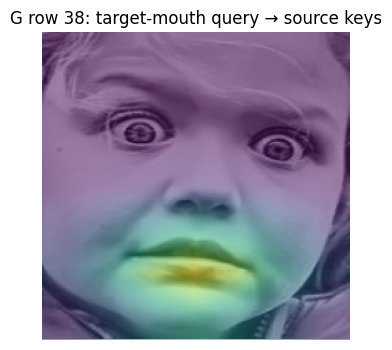

In [5]:
import torch

def add_au_bias(logits, G, lam):
    if G is None:
        return logits
    expected = (logits.shape[0], logits.shape[-2], logits.shape[-1])
    if tuple(G.shape) != expected:
        raise ValueError(f"G must have shape {expected}, got {tuple(G.shape)}")
    return logits + lam.view(1, -1, 1, 1) * G[:, None].to(logits)

# Contract test matching Swin-T stage 4: B x 24 heads x 49 x 49.
B, H, N, C = 2, 24, 49, len(AUS)
row_by_id = {row["sample_id"]: row for row in rows if row["usable"]}
paired_rows = [row_by_id[sample_id] for sample_id in df["sample_id"][:2 * B]]
M_t = np.stack([build_M(row) for row in paired_rows[:B]])
M_s = np.stack([build_M(row) for row in paired_rows[B:]])
G_ts = torch.from_numpy(compute_G(P[:B], P[B:2 * B], M_t, M_s))
logits = torch.randn(B, H, N, N)
lam = torch.zeros(H, requires_grad=True)
assert G_ts.shape == (B, N, N)
assert torch.equal(add_au_bias(logits, G_ts, lam), logits)
assert add_au_bias(logits, G_ts.transpose(-2, -1), torch.ones(H)).shape == logits.shape
print("G contract OK:", tuple(G_ts.shape), "lambda=0 preserves POST")

# Inspect one G row only after M_mouth and M_eye have been checked above.
mouth_query = int(M_t[0, :, AUS.index(12)].argmax())
G_mouth_row = G_ts[0, mouth_query].numpy().reshape(GRID, GRID)
with Image.open(MANIFEST.parent / paired_rows[B]["processed_path"]) as image:
    source_face_224 = image.convert("RGB").resize((224, 224), Image.Resampling.BILINEAR)
plt.figure(figsize=(4, 4))
plt.imshow(source_face_224)
plt.imshow(G_mouth_row, extent=(0, 224, 224, 0), interpolation="bilinear",
           alpha=0.5, cmap="viridis")
plt.title(f"G row {mouth_query}: target-mouth query → source keys")
plt.xlim(0, 224); plt.ylim(224, 0); plt.axis("off")
plt.show()

## 7. Sanity checks before training

Join AU rows to manifests by `sample_id`, never by CSV row order. Report LibreFace failures and use `G=0` for those samples. AU should broadly agree with labelled RAF-DB expressions, and source/target AU distributions should be checked for drift. ExpW labels are for offline diagnosis only. Before training, also verify that the image and landmark mask share the same random flip and that `au_lambda=0` reproduces all four current BCS outputs.

In [6]:
CLASSES = ["anger", "disgust", "fear", "happiness", "neutral", "sadness", "surprise"]  # repo order

def au_by_class(P, labels, aus=AUS, class_names=CLASSES):
    out = pd.DataFrame(P, columns=[f"AU{a}" for a in aus])
    out["label"] = labels
    t = out.groupby("label").mean()
    t.index = [class_names[i] if isinstance(i, (int, np.integer)) and i < len(class_names) else i for i in t.index]
    return t.round(2)

# labels_src = ...   # array of int labels aligned with the rows of df (RAF-DB)
# print(au_by_class(P, labels_src))
# expected, roughly: happiness -> AU12/AU6; anger -> AU4; surprise -> AU1/2/5/26

def compare_domains(P_src, P_tgt, aus=AUS):
    t = pd.DataFrame({
        "src_mean": P_src.mean(0), "tgt_mean": P_tgt.mean(0),
        "src_std":  P_src.std(0),  "tgt_std":  P_tgt.std(0),
    }, index=[f"AU{a}" for a in aus]).round(3)
    t["mean_gap"] = (t.tgt_mean - t.src_mean).abs().round(3)
    return t

# P_src = au_matrix(pd.read_csv("/data/au/rafdb.csv"))
# P_tgt = au_matrix(pd.read_csv("/data/au/expw.csv"))
# print(compare_domains(P_src, P_tgt))

# Also report: fraction of images LibreFace failed to process (missing rows). For those set G = 0 => falls back to POST.